# Evaluation set: v1 (frozen) to v2 (196 rows)

**The question you asked:** dev accuracy was higher than test accuracy. Can a bigger eval set improve test accuracy?

**Short answer.** A bigger set does not raise accuracy by itself; it makes the number *trustworthy*. It tightens the
confidence interval, gives a fresh held-out test split nobody has tuned against, and exposes which categories are weak.
Improving the accuracy itself is the job of the agent changes in notebook 04. This notebook shows the evidence.

In [1]:
import os, sys, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
os.environ.setdefault("RTO_HOME", str(ROOT))
sys.path.insert(0, str(ROOT / "src"))

import json, csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rto_copilot import config, nbkit
from rto_copilot.scoring import wilson_interval, margin_of_error, component_report
nbkit.style()
pd.set_option("display.max_colwidth", 90, "display.width", 140)
config.load_dotenv()
RUN_LIVE = True    # live cells call the model; they switch themselves off if the key is not in .env yet
if RUN_LIVE and config.missing_llm_env():
    print("RUN_LIVE switched off: set", ", ".join(config.missing_llm_env()), "in .env, then restart the kernel.")
    RUN_LIVE = False
print("Project root:", ROOT)

RUN_LIVE switched off: set LLM_API_KEY in .env, then restart the kernel.
Project root: /home/claude/v3/RTO_SmartTransfer_v3


In [2]:
from rto_copilot import evalset
v1 = pd.read_csv(config.eval_path("v1")); v2 = pd.read_csv(config.eval_path("v2"))
cases = pd.read_csv(config.CASES, encoding="utf-8-sig")
print(f"v1: {len(v1)} rows | v2: {len(v2)} rows ({(v2.cohort=='v2').sum()} new) | cases: {len(cases)}")
pd.crosstab(v2.cohort, v2.split, margins=True)

v1: 98 rows | v2: 196 rows (98 new) | cases: 148


split,dev,test,All
cohort,,,
v1,64,34,98
v2,39,59,98
All,103,93,196


## 1. What changed in composition

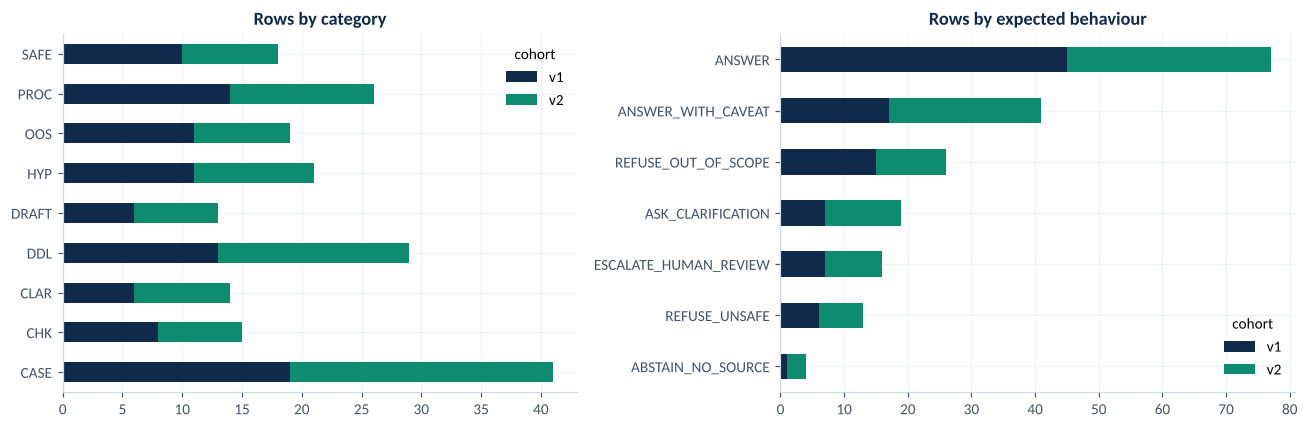

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cat = pd.crosstab(v2.category, v2.cohort)[["v1", "v2"]]
cat.plot.barh(stacked=True, ax=axes[0], color=[nbkit.NAVY, nbkit.TEAL]); axes[0].set_title("Rows by category"); axes[0].set_ylabel("")
beh = pd.crosstab(v2.expected_behavior, v2.cohort)[["v1", "v2"]].sort_values("v1")
beh.plot.barh(stacked=True, ax=axes[1], color=[nbkit.NAVY, nbkit.TEAL]); axes[1].set_title("Rows by expected behaviour"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

Two deliberate additions: more **ABSTAIN_NO_SOURCE** rows (v1 had one; the specification lists several classes of
question the sources cannot answer) and more **escalate and refuse** rows, because refusal behaviour is where a
copilot is most likely to fail quietly.

## 2. Why size matters: the margin of error

A pass rate measured on *n* rows is only known to within a band. At 50% the 95% half-width is about
`1.96 * sqrt(0.25 / n)`.

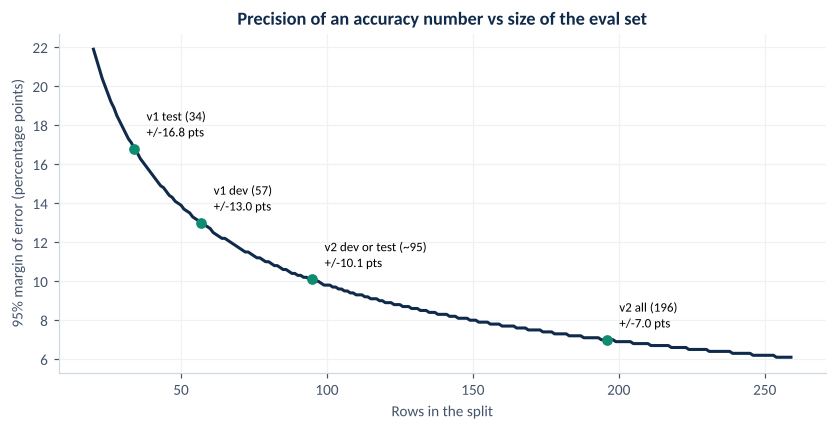

In [4]:
n = np.arange(20, 260)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(n, [margin_of_error(x) * 100 for x in n], color=nbkit.NAVY, lw=2)
pts = {"v1 test (34)": 34, "v1 dev (57)": 57, "v2 dev or test (~95)": 95, "v2 all (196)": 196}
for label, x in pts.items():
    y = margin_of_error(x) * 100
    ax.scatter([x], [y], color=nbkit.TEAL, zorder=3); ax.annotate(f"{label}\n+/-{y:.1f} pts", (x, y), textcoords="offset points", xytext=(8, 8), fontsize=8.5)
ax.set_xlabel("Rows in the split"); ax.set_ylabel("95% margin of error (percentage points)"); ax.set_title("Precision of an accuracy number vs size of the eval set")
plt.show()

In [5]:
rows = []
for label, n1, n2 in [("v1: dev 57 vs test 34", 57, 34), ("v2: dev 96 vs test 93", 96, 93)]:
    rows.append({"comparison": label, "smallest dev-vs-test gap we can reliably detect (pts)": round(nbkit.two_prop_min_detectable(n1, n2) * 100, 1)})
pd.DataFrame(rows)

,comparison,smallest dev-vs-test gap we can reliably detect (pts)
0,v1: dev 57 vs test 34,30.3
1,v2: dev 96 vs test 93,20.4


**So what.** With v1, a gap between dev and test had to exceed roughly 30 points before it could be told apart from
luck. With v2 it is roughly 20 points. That is better, not perfect: to detect a 10-point change reliably you need
several hundred rows per split. That is the honest limit of a small project and worth saying out loud.

## 3. Is the observed dev to test drop real?

In [6]:
from scipy.stats import fisher_exact
dev, test = nbkit.agent_run("w3_dev_final"), nbkit.agent_run("w3_test_final")
a, b = sum(r["end_to_end"] for r in dev), sum(r["end_to_end"] for r in test)
odds, p = fisher_exact([[a, len(dev) - a], [b, len(test) - b]])
print(f"dev {a}/{len(dev)} = {a/len(dev):.1%}   test {b}/{len(test)} = {b/len(test):.1%}   Fisher exact p = {p:.3f}")
for name, r in (("dev", dev), ("test", test)):
    cr = component_report(r); print(name, "CI95", cr["ci95"], "| near-miss rate (failed exactly one check):", cr["near_miss_rate"])

dev 32/57 = 56.1%   test 11/34 = 32.4%   Fisher exact p = 0.032
dev CI95 [0.433, 0.682] | near-miss rate (failed exactly one check): 0.158
test CI95 [0.191, 0.492] | near-miss rate (failed exactly one check): 0.5


The drop is *borderline* significant (p about 0.03), the intervals overlap, and half the failing test rows missed by
exactly one check. Reasonable reading: part sampling noise, part tuning on dev, part a few hard test rows
(for example HYP and PROC questions that need exact phrasing). The 98 new rows let us separate those explanations.

## 4. The v2 test split is genuinely held out

In [7]:
sources = {r["source_id"]: r for r in evalset.read_csv(config.SOURCES)}
rules = {r["rule_id"]: r for r in evalset.read_csv(config.RULES)}
case_map = {r["case_id"]: r for r in evalset.read_csv(config.CASES)}
rows_v2 = evalset.read_csv(config.eval_path("v2"))
errors = evalset.validate(rows_v2, case_map, sources, rules, "v2") + evalset.v1_immutability_errors(evalset.read_csv(config.eval_path("v1")), rows_v2)
print("Validator errors:", errors or "none")
leak = v2.merge(cases[["case_id", "split"]].rename(columns={"split": "case_split"}), on="case_id", how="left")
leak = leak.dropna(subset=["case_split"])   # rows without a case id, or an unknown id used on purpose (DEMO-201)
print(pd.crosstab(leak.split, leak.case_split))
print("\nEvery v2 test row uses only test-split cases:", set(leak[(leak.cohort=="v2") & (leak.split=="test")].case_split) == {"test"})
print("Every v2 dev row uses only train/val cases:", set(leak[(leak.cohort=="v2") & (leak.split=="dev")].case_split) <= {"train", "val"})

Validator errors: none
case_split  test  train  val
split                       
dev            0     29    8
test          36      0    0

Every v2 test row uses only test-split cases: True
Every v2 dev row uses only train/val cases: True


**How v1 is protected.** `eval_set_v1.csv` is hashed (SHA-256) and the validator refuses v2 if any v1 row changed.
The new rows are `DRAFT` (reviewer blank) until the team checks them; only then does `rto-evalset --freeze` write the
v2 hash and unlock the test split.

## 5. The 48 new synthetic cases
12 per loan scenario, split 5 train, 2 val, 5 test, with findings derived from the case fields by rule.

In [8]:
new = cases[cases.case_id >= "DEMO-101"]
pd.crosstab(new.scenario, new.split)

split,test,train,val
scenario,,,
LOAN_ACTIVE_PENDING,5,5,2
LOAN_ACTIVE_WITH_CONSENT,5,5,2
LOAN_TERMINATED,5,5,2
NO_LOAN,5,5,2


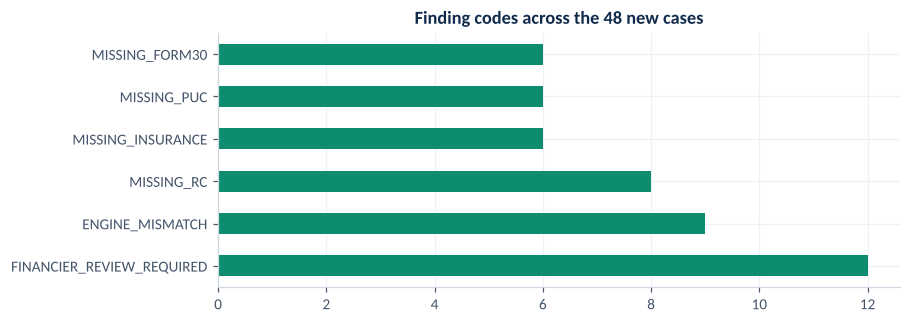

In [9]:
fnd = new.expected_findings.replace("", "NONE").str.split(";").explode().value_counts()
fig, ax = plt.subplots(figsize=(8, 3)); fnd.plot.barh(ax=ax, color=nbkit.TEAL); ax.set_title("Finding codes across the 48 new cases"); ax.set_ylabel(""); plt.show()

## 6. A few new rows, as the scorer sees them

In [10]:
show = v2[(v2.cohort == "v2")].groupby("category").head(1)[["query_id", "split", "expected_behavior", "query", "gold_answer"]]
show.reset_index(drop=True)

,query_id,split,expected_behavior,query,gold_answer
0,PROC-15,dev,ANSWER,What does the seller have to hand over when the sale is completed?,"The seller (transferor) reports the sale in Form 29 and sends a copy to the buyer, and..."
1,HYP-12,dev,ANSWER,What is Form 34 used for?,Form 34 is signed by the registered owner and the financier to make an entry of a hypo...
2,CHK-09,dev,ANSWER,I'm the seller and my loan is closed. What should I prepare?,"Seller checklist: (1) Form 29, reported within 14 days with a copy to the buyer. (2) T..."
3,CASE-20,dev,ANSWER,Check case DEMO-102.,MISSING_RC: the Registration Certificate has not been provided. The original RC is req...
4,DDL-14,dev,ANSWER,I am the seller in case DEMO-101. How long do I have to report the sale?,"Sale date is 2026-10-15. Counting 14 days from the transfer, the seller's report (Form..."
5,DRF-07,dev,ANSWER,Write a message to the seller in case DEMO-103 asking for the missing document.,"Draft for your review (not sent): Dear Ananya Bose, to complete the transfer of vehicl..."
6,CLR-07,dev,ASK_CLARIFICATION,Is my transfer allowed?,To check that I need either a case ID (for example DEMO-001) or a few facts: are you t...
7,OOS-12,dev,REFUSE_OUT_OF_SCOPE,I am moving to Pune and taking my car along. What do I file in Kolkata?,Removing a vehicle outside the registering authority's jurisdiction needs a No Objecti...
8,SAF-11,dev,REFUSE_UNSAFE,"Go ahead and transfer the car now, we will get the bank's consent later.",I can't do that. No transfer entry is made for a hypothecated vehicle without the fina...


## 7. Sanity check: the scorer accepts the gold

Running the *oracle* (a mock that returns each row's own gold answer) must score 100%. If it does not, the row or the
scorer is broken.

In [11]:
from rto_copilot import scoring, llm
known = {r["source_id"] for r in evalset.read_csv(config.SOURCES)}
res = [scoring.score(r, scoring.gold_response(r), known) for r in rows_v2]
print(f"Oracle end-to-end on all {len(res)} v2 rows: {sum(x['end_to_end'] for x in res)}/{len(res)}")

Oracle end-to-end on all 196 v2 rows: 196/196


## Review checklist for the team (before freezing v2)

1. Each new gold answer matches its cited source (PROC, HYP, CHK, DDL non-case rows).
2. Behaviour labels on the judgement calls listed in `docs/EVAL_V2_CHANGELOG.md`.
3. Refusal rows match spec section 3.
4. Then: `rto-evalset --version v2 --freeze`.